In [39]:
import datetime
import pandas as pd
import lseg.data as ld
import matplotlib.pyplot as plt

In [40]:
ld.open_session()

<lseg.data.session.Definition object at 0x142b34dfb60 {name='rdp'}>

In [45]:
start_date = datetime.datetime.now() - datetime.timedelta(5000)
end_date = datetime.datetime.now()

df = ld.get_history(
    universe="EUR=",
    fields=["MID_PRICE"],
    interval="daily",
    start=start_date,
    end=end_date,
)

df["CHANGES"] = df["MID_PRICE"].pct_change()
df["STD_DEV"] = df["CHANGES"].dropna()
df["STD_DEV"] = (df["STD_DEV"] - df["STD_DEV"].mean()) / df["STD_DEV"].std()

df

EUR=,MID_PRICE,CHANGES,STD_DEV
Date,,,
2012-11-16,1.27435,<NA>,<NA>
2012-11-19,1.28135,0.005493,1.152102
2012-11-20,1.28175,0.000312,0.069525
2012-11-21,1.2829,0.000897,0.191774
2012-11-22,1.28835,0.004248,0.891988
...,...,...,...
2026-07-20,1.1415,-0.002142,-0.443232
2026-07-21,1.13985,-0.001445,-0.297748
2026-07-22,1.14115,0.001141,0.242611


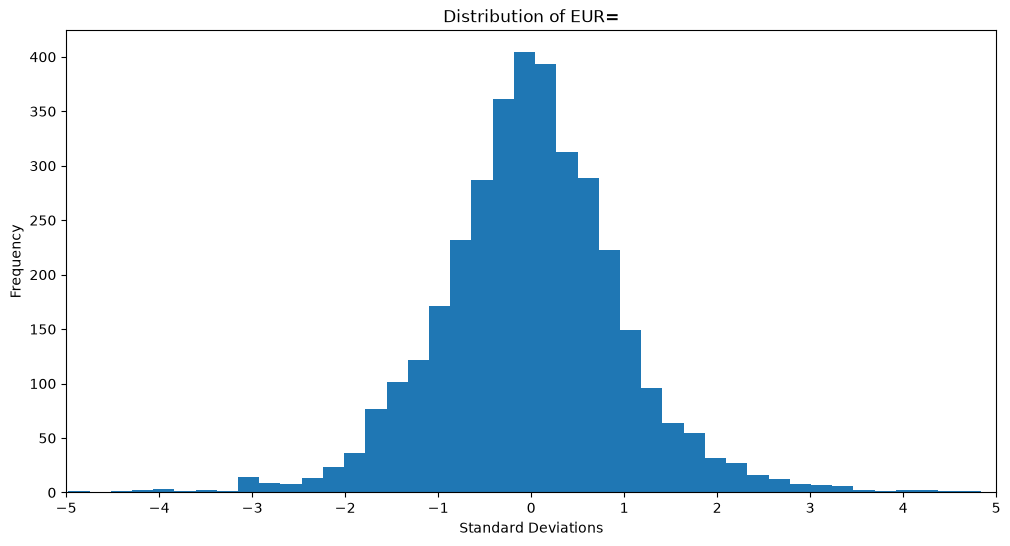

In [50]:
plt.figure(figsize=(12,6))
plt.hist(df["STD_DEV"], bins=50)
plt.xlim(-5, 5)
plt.xticks(range(-5, 6, 1))

plt.title(f"Distribution of {df.columns.name}")
plt.xlabel("Standard Deviations")
plt.ylabel("Frequency")
plt.show()